# Credit Risk Analytics — Final Project Report and Executive Summary

This eighth and final notebook consolidates the completed analytical notebook series into a business-oriented review. It reports verified results from Notebooks 01–07, adds only limited purposeful visualizations, and distinguishes demonstrated findings from assumptions and recommendations.

## 1. Project Title and Executive Summary

### Business problem

Credit-card providers need to identify accounts that may require closer monitoring or customer support because a future payment default can create financial loss and customer harm.

### Analytical objective

This capstone investigated whether historical demographic, credit-limit, repayment-status, billing, and payment variables can support research-oriented prediction of `default payment next month`.

### Approach and principal result

The project progressed from data understanding and exploratory analysis through leakage-aware preprocessing, model comparison, interpretability, final review, and robustness validation. The selected model is a Random Forest Classifier with a 0.55 decision threshold. On the established held-out test split it achieved Accuracy 0.8015, Precision 0.5532, Recall 0.5328, F1-score 0.5428, and ROC-AUC 0.7762.

The model may support risk monitoring and manual-review prioritization. It does not prove causation, guarantee calibrated probabilities, establish fairness, or justify automatic lending decisions. External validation, calibration, fairness assessment, temporal testing, and production governance remain necessary.

## 2. Business Problem and Project Objectives

The classification task is to distinguish customers who did and did not default on the following month's payment. A false positive is a non-default customer flagged for review; a false negative is a default customer missed by the model. These errors have different operational and customer consequences.

Because default is the minority class, accuracy alone is insufficient. Precision, recall, F1-score, ROC-AUC, and the confusion matrix provide a more informative view. The model is a decision-support signal, not an automatic approval, rejection, pricing, or collections decision.

## 3. Dataset Overview

The project uses the UCI Default of Credit Card Clients dataset supplied as `data/default of credit card clients.xls`. After promoting the workbook's first row to the header, the dataset contains 30,000 observations and 25 columns: 23 predictors, an identifier, and the target.

The target is `default payment next month`:

- Non-default: 23,364 customers (77.88%)
- Default: 6,636 customers (22.12%)

Feature groups include demographics (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`), credit limit, six historical repayment-status variables, six billing-amount variables, and six payment-amount variables. The data-understanding work found no missing values and retained unusual negative billing values for analysis rather than silently deleting them. The dataset is historical and geographically specific; it should not be described as representative of modern global credit markets.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
current_directory = Path.cwd()
project_root = current_directory.parent if current_directory.name.lower() == "notebooks" else current_directory
data_path = project_root / "data" / "default of credit card clients.xls"
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {data_path}")

raw_data = pd.read_excel(data_path)
data = raw_data.copy()
data.columns = data.iloc[0].astype(str).str.strip()
data = data.iloc[1:].reset_index(drop=True).apply(pd.to_numeric)

target_column = "default payment next month"
target_counts = data[target_column].value_counts().sort_index()
print("Dataset shape:", data.shape)
print("Missing values:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))
display(pd.DataFrame({"Customers": target_counts, "Percentage": target_counts / len(data) * 100}).round(2))

Dataset shape: (30000, 25)
Missing values: 0
Duplicate rows: 0


,Customers,Percentage
default payment next month,,
0,23364,77.88
1,6636,22.12


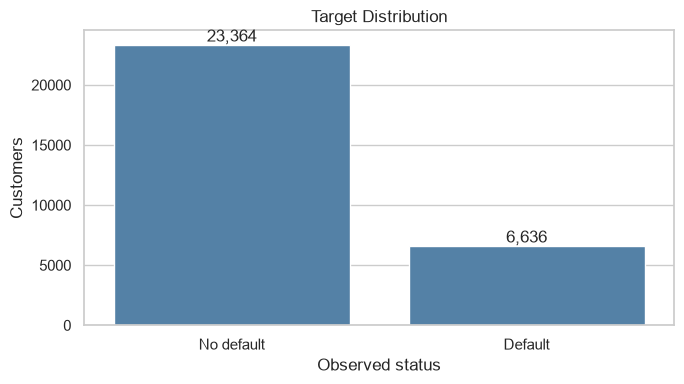

In [2]:
target_plot = pd.DataFrame({"Status": ["No default", "Default"], "Customers": [target_counts.get(0, 0), target_counts.get(1, 0)]})
plt.figure(figsize=(7, 4))
sns.barplot(data=target_plot, x="Status", y="Customers", color="steelblue")
plt.title("Target Distribution")
plt.xlabel("Observed status")
plt.ylabel("Customers")
for index, value in enumerate(target_plot["Customers"]):
    plt.text(index, value + 250, f"{value:,}", ha="center")
plt.tight_layout()
plt.show()

## 4. Key Exploratory Data Analysis Findings

The exploratory analysis identified the following evidence-supported patterns:

- Default is a minority outcome, creating an imbalanced classification problem.
- Historical repayment-status variables show strong associations with default rates and are central to risk interpretation.
- Credit limits, billing amounts, and payment amounts vary substantially and include skewed financial distributions.
- Payment and billing behaviour differs between observed default classes, but these differences are associations rather than causal effects.
- Demographic groups show different observed rates in this dataset; these differences require careful governance and do not establish that demographic attributes cause default.

The final report intentionally avoids repeating the full exploratory notebook and uses only the target-distribution chart above as a concise context visual.

## 5. Data Preprocessing Methodology

The established workflow used an 80/20 stratified train/test split with `random_state=42` and excluded `ID` from predictors. Category codes were standardized by grouping education codes 0, 5, and 6 into 4, and marriage code 0 into 3.

The preprocessing pipeline used:

- `OneHotEncoder(handle_unknown="ignore")` for nominal demographic and repayment-status variables.
- `StandardScaler` for `AGE` and `LIMIT_BAL`.
- Yeo-Johnson `PowerTransformer`, followed by `StandardScaler`, for billing and payment amounts.

The transformation pipeline was fitted on training data within model pipelines, preventing test information from influencing preprocessing. Threshold selection was performed using validation data in Notebook 04 rather than tuning on the held-out test set.

## 6. Model Development and Comparison

Notebook 04 evaluated a dummy baseline, Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. The following table reproduces its verified default-threshold comparison results. Threshold-sensitive metrics are shown here as the reported model-comparison values; the final Random Forest decision was subsequently evaluated at threshold 0.55.

In [3]:
model_comparison = pd.DataFrame({
    "Accuracy": [0.7788, 0.7640, 0.7448, 0.7817, 0.8157],
    "Precision": [0.0000, 0.4737, 0.4429, 0.5056, 0.6647],
    "Recall": [0.0000, 0.6051, 0.5961, 0.5818, 0.3361],
    "F1-score": [0.0000, 0.5314, 0.5082, 0.5410, 0.4464],
    "ROC-AUC": [0.5000, 0.7708, 0.7444, 0.7762, 0.7745],
}, index=["Dummy Classifier", "Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"])
display(model_comparison.round(4))
print("The selected model is Random Forest because it provided the strongest reported F1-score among the untuned comparison results and was further evaluated through validation-based threshold analysis.")

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Dummy Classifier,0.7788,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7640,0.4737,0.6051,0.5314,0.7708
Decision Tree,0.7448,0.4429,0.5961,0.5082,0.7444
Random Forest,0.7817,0.5056,0.5818,0.5410,0.7762
Gradient Boosting,0.8157,0.6647,0.3361,0.4464,0.7745


The selected model is Random Forest because it provided the strongest reported F1-score among the untuned comparison results and was further evaluated through validation-based threshold analysis.


## 7. Final Model Performance

The selected Random Forest configuration is `n_estimators=200`, `max_depth=12`, `class_weight="balanced"`, `random_state=42`, and `n_jobs=-1`, evaluated at threshold 0.55.

Verified held-out test results:

- Accuracy: 0.8015
- Precision: 0.5532
- Recall: 0.5328
- F1-score: 0.5428
- ROC-AUC: 0.7762
- Confusion matrix: TN 4,102; FP 571; FN 620; TP 707

The 620 false negatives show that the model misses a meaningful proportion of observed defaults. The 571 false positives show that identifying more potential defaults also creates review burden for some customers who did not default. The acceptable balance depends on documented business costs and governance requirements.

In [4]:
final_metrics = pd.Series({"Accuracy": 0.8015, "Precision": 0.5532, "Recall": 0.5328, "F1-score": 0.5428, "ROC-AUC": 0.7762})
confusion_matrix = pd.DataFrame([[4102, 571], [620, 707]], index=["Actual no default", "Actual default"], columns=["Predicted no default", "Predicted default"])
display(final_metrics.to_frame("Held-out test score").round(4))
display(confusion_matrix)

,Held-out test score
Accuracy,0.8015
Precision,0.5532
Recall,0.5328
F1-score,0.5428
ROC-AUC,0.7762


,Predicted no default,Predicted default
Actual no default,4102,571
Actual default,620,707


## 8. Model Interpretability

Notebook 05 calculated held-out permutation importance using F1-score. The leading original input features were:

1. `PAY_0`
2. `PAY_2`
3. `PAY_AMT2`
4. `PAY_AMT3`
5. `PAY_AMT1`

This supports the practical observation that recent repayment history and payment behaviour are important model-used signals. Importance does not provide relationship direction and does not prove causation. Correlated financial variables can share or redistribute importance, and impurity-based importance has different limitations from permutation importance.

## 9. Customer Risk Segmentation

Notebook 05 used illustrative predicted-risk boundaries:

- **Low predicted risk:** probability below 0.25
- **Medium predicted risk:** probability from 0.25 to below 0.50
- **High predicted risk:** probability at least 0.50

These are analytical groupings, not validated credit-policy thresholds. Scores were not shown to be calibrated default probabilities. Verified held-out segment results were:

| Segment | Customers | Population | Observed default rate | Average model score |
|---|---:|---:|---:|---:|
| Low predicted risk | 1,407 | 23.45% | 5.76% | 0.2013 |
| Medium predicted risk | 3,066 | 51.10% | 15.46% | 0.3548 |
| High predicted risk | 1,527 | 25.45% | 50.56% | 0.7082 |

The increasing observed rates support using the segments for research-oriented prioritization, not automatic lending action.

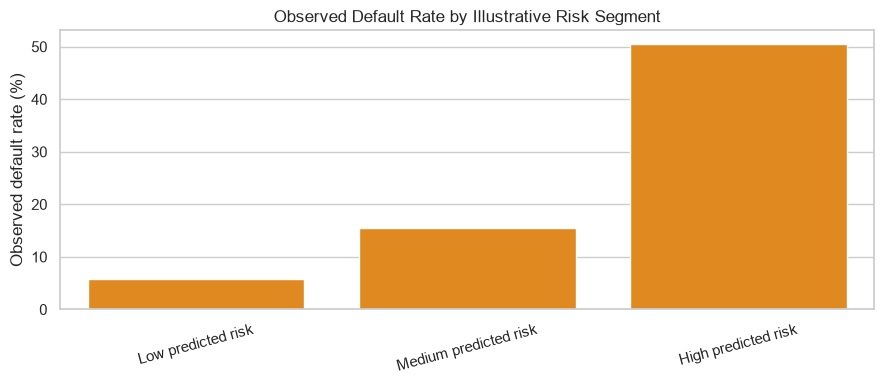

In [5]:
segment_table = pd.DataFrame({"Segment": ["Low predicted risk", "Medium predicted risk", "High predicted risk"], "Customers": [1407, 3066, 1527], "Observed default rate (%)": [5.7569, 15.4599, 50.5566]})
plt.figure(figsize=(9, 4))
sns.barplot(data=segment_table, x="Segment", y="Observed default rate (%)", color="darkorange")
plt.title("Observed Default Rate by Illustrative Risk Segment")
plt.xlabel("")
plt.ylabel("Observed default rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Robustness and Validation

Notebook 07 used five-fold shuffled `StratifiedKFold` cross-validation with `random_state=42`, fitting preprocessing independently inside each fold. The verified validation summary was:

| Metric | Mean | Standard deviation | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Accuracy | 0.7838 | 0.0032 | 0.7794 | 0.7875 |
| Precision | 0.5100 | 0.0064 | 0.5012 | 0.5169 |
| Recall | 0.5818 | 0.0088 | 0.5734 | 0.5919 |
| F1-score | 0.5435 | 0.0054 | 0.5374 | 0.5518 |
| ROC-AUC | 0.7825 | 0.0065 | 0.7726 | 0.7897 |

Out-of-fold average precision was 0.5554 and the out-of-fold Brier score was 0.1697. The calibration curve was examined, but the project does not claim that probabilities are calibrated.

Descriptive subgroup evaluation on the held-out test set reported:

- Gender: Female, n=3,598, F1=0.5459; Male, n=2,402, F1=0.5386.
- Age groups: F1 ranged from 0.5227 for ages 56+ (n=178) to 0.5617 for ages up to 25 (n=767).

These results suggest low fold-to-fold variability but do not establish temporal generalization, calibration, or comprehensive fairness.

,Mean,Std
Accuracy,0.7838,0.0032
Precision,0.5100,0.0064
Recall,0.5818,0.0088
F1-score,0.5435,0.0054
ROC-AUC,0.7825,0.0065


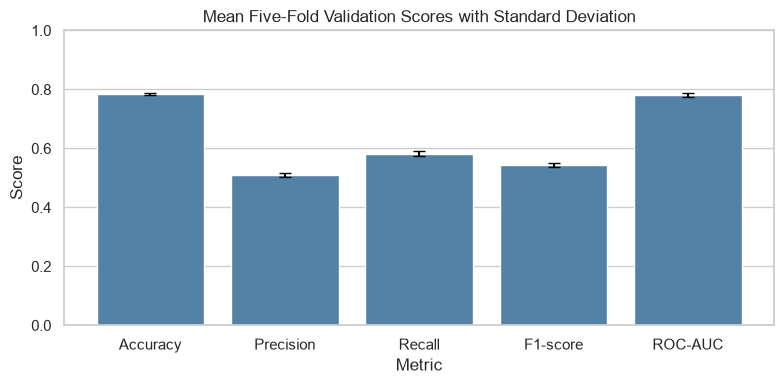

In [6]:
validation_summary = pd.DataFrame({"Mean": [0.7838, 0.5100, 0.5818, 0.5435, 0.7825], "Std": [0.0032, 0.0064, 0.0088, 0.0054, 0.0065]}, index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"])
display(validation_summary)
plt.figure(figsize=(8, 4))
sns.barplot(data=validation_summary.reset_index(), x="index", y="Mean", color="steelblue")
plt.errorbar(np.arange(len(validation_summary)), validation_summary["Mean"], yerr=validation_summary["Std"], fmt="none", color="black", capsize=4)
plt.title("Mean Five-Fold Validation Scores with Standard Deviation")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 11. Business Recommendations

1. Use model scores and illustrative segments to prioritize manual review and targeted risk monitoring, not to automate adverse lending decisions.
2. Evaluate threshold choices against explicit business costs for false positives, false negatives, customer support, and credit loss.
3. Investigate calibration before using scores as likelihoods or assigning probability-based interventions.
4. Monitor subgroup performance and investigate material differences with appropriate uncertainty and governance review.
5. Test the model on more recent and external data before relying on it for current portfolios.
6. Keep the preprocessing pipeline, model version, threshold, and decision policy traceable together.

## 12. Project Limitations

- The dataset is historical and geographically specific to Taiwan; it may not generalize to other populations or current portfolios.
- The class imbalance makes accuracy alone inadequate.
- The false-negative count is material and may represent missed opportunities for intervention or increased credit loss.
- Calibration was investigated but not established.
- Subgroup sample sizes and selected demographic slices are incomplete for fairness assessment.
- There is no external or temporal validation in this project.
- Correlated predictors limit simplistic feature-importance interpretation.
- Potential data drift, changing customer behaviour, and changing economic conditions could reduce future performance.
- Production use would require governance, privacy and regulatory review, monitoring, documentation, human oversight, and an approved decision policy.

The demonstrated findings are the measured results above. Recommendations and deployment implications are conditional proposals, not evidence that the model is production-ready.

## 13. Future Improvements

Realistic next steps include temporal and external validation, probability calibration, cost-sensitive threshold evaluation on validation data, additional feature engineering, controlled hyperparameter optimization, drift monitoring, expanded intersectional fairness analysis, uncertainty estimation, and a formal deployment-readiness assessment. These improvements are not implemented in this final report notebook.

## 14. Final Executive Conclusion

This capstone investigated whether historical credit-card information could support prediction of next-month default. The completed workflow covered data quality, EDA, leakage-aware preprocessing, model comparison, interpretability, risk segmentation, final review, and robustness validation.

The selected Random Forest at threshold 0.55 achieved 0.8015 accuracy, 0.5532 precision, 0.5328 recall, 0.5428 F1-score, and 0.7762 ROC-AUC on the established held-out test set, with 620 false negatives and 571 false positives. Cross-validation showed low fold-to-fold variability, while calibration, fairness, generalization, and production readiness remain unresolved.

The model could provide business value as a research-oriented prioritization and monitoring aid, subject to human review and governance. It should not be treated as an automatic lending decision system. This notebook concludes the analytical notebook series for the Credit Risk Analytics capstone.

In [7]:
print("Final executive summary completed.")
print("Selected model: Random Forest, threshold 0.55")
print("Held-out metrics:")
print(final_metrics.round(4).to_string())
print("The project concludes with documented limitations around calibration, fairness, external validation, drift, and production governance.")

Final executive summary completed.
Selected model: Random Forest, threshold 0.55
Held-out metrics:
Accuracy     0.8015
Precision    0.5532
Recall       0.5328
F1-score     0.5428
ROC-AUC      0.7762
The project concludes with documented limitations around calibration, fairness, external validation, drift, and production governance.
